#Disease Diagnosis Support System Using Machine Learning


Course: IS 110 – Machine Learning
Milestone: B and C – Exploration and Preparation
Submission Date: November 19, 2026

Group Members:

John Feneo Christian Abrot

Jhanice Briongos

Zeam Clarito

Angel Marie Limas

Hanni Grace Villa

##Project Description

This notebook focuses on exploring and preparing the Disease Symptoms and Patient Profile Dataset for machine learning. The dataset will be examined to understand its structure, identify data quality issues, analyze disease distributions, and prepare the features for disease classification. The prepared dataset will be used in the next stage for comparing different machine learning algorithms.

##Exploration (Section B)

###B1. Dataset loading and inspection

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


The dataset will be loaded and examined to understand its structure, including the number of records, available features, data types, and sample observations. This initial inspection will help determine the appropriate methods for data analysis and preparation.

In [6]:
%cd /content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic/PythonEnvi_AI

/content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic/PythonEnvi_AI


In [7]:
%pwd

'/content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic/PythonEnvi_AI'

In [8]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic/PythonEnvi_AI/Datasets/Disease_symptom_and_patient_profile_dataset.csv")
print(df.shape)
print(df.columns.tolist())

(349, 10)
['Disease', 'Fever', 'Cough', 'Fatigue', 'Difficulty Breathing', 'Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Outcome Variable']


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

df = pd.read_csv("/content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic/PythonEnvi_AI/Datasets/Disease_symptom_and_patient_profile_dataset.csv")

print("Dataset Shape:", df.shape)
display(df.head())
df.info()

Dataset Shape: (349, 10)


,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
0,Influenza,Yes,No,Yes,Yes,19,Female,Low,Normal,Positive
1,Common Cold,No,Yes,Yes,No,25,Female,Normal,Normal,Negative
2,Eczema,No,Yes,Yes,No,25,Female,Normal,Normal,Negative
3,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive
4,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349 entries, 0 to 348
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Disease               349 non-null    object
 1   Fever                 349 non-null    object
 2   Cough                 349 non-null    object
 3   Fatigue               349 non-null    object
 4   Difficulty Breathing  349 non-null    object
 5   Age                   349 non-null    int64 
 6   Gender                349 non-null    object
 7   Blood Pressure        349 non-null    object
 8   Cholesterol Level     349 non-null    object
 9   Outcome Variable      349 non-null    object
dtypes: int64(1), object(9)
memory usage: 27.4+ KB


###B2. Descriptive statistics

Descriptive statistics will be generated to summarize the numerical and categorical variables. This will help identify the general characteristics and distribution of the patient information.

In [11]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Disease,349,116,Asthma,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fever,349,2,Yes,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cough,349,2,No,182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fatigue,349,2,Yes,242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Difficulty Breathing,349,2,No,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,349.0,NaN,NaN,NaN,46.323782,13.08509,19.0,35.0,45.0,55.0,90.0
Gender,349,2,Female,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Pressure,349,3,High,167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cholesterol Level,349,3,High,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outcome Variable,349,2,Positive,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN


###B3. Identify missing values

The dataset will be checked for missing values to determine which features require data cleaning or imputation before model development.

In [12]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})
display(missing)
print("Total missing values:", int(df.isna().sum().sum()))

,Missing values,Missing (%)
Disease,0,0.0
Fever,0,0.0
Cough,0,0.0
Fatigue,0,0.0
Difficulty Breathing,0,0.0
Age,0,0.0
Gender,0,0.0
Blood Pressure,0,0.0
Cholesterol Level,0,0.0
Outcome Variable,0,0.0


Total missing values: 0


###B4. Check duplicate records

Duplicate records will be identified to determine whether repeated patient observations are present in the dataset. These records will be examined because duplicates may affect the reliability of model evaluation.

In [13]:
n_dup = df.duplicated().sum()
print("Duplicate rows (extra copies):", n_dup, f"({n_dup / len(df) * 100:.1f}%)")
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(20))

Duplicate rows (extra copies): 49 (14.0%)


,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
311,Alzheimer's Disease,No,Yes,No,No,65,Male,Normal,High,Positive
312,Alzheimer's Disease,No,Yes,No,No,65,Male,Normal,High,Positive
327,Alzheimer's Disease,Yes,No,Yes,No,70,Female,High,Normal,Negative
328,Alzheimer's Disease,Yes,No,Yes,No,70,Female,High,Normal,Negative
58,Asthma,No,Yes,Yes,Yes,35,Female,High,Normal,Negative
59,Asthma,No,Yes,Yes,Yes,35,Female,High,Normal,Negative
125,Asthma,Yes,No,Yes,Yes,40,Male,Normal,High,Positive
126,Asthma,Yes,No,Yes,Yes,40,Male,Normal,High,Positive
3,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive
4,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive


###B5. Examine outliers

Numeric features will be examined using boxplots to identify possible extreme values. The Interquartile Range method will also be used to count potential outliers.

The relationships between the independent features were examined to identify possible redundancy and strong associations. Since most of the dataset's variables are categorical, Cramér's V was used to measure associations between categorical features. Age was treated as a numerical variable and examined separately. This analysis helps determine whether some features provide overlapping information that may affect model interpretation.

IQR bounds: 5.0 to 85.0
Potential Age outliers: 2


,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
347,Stroke,Yes,No,Yes,No,90,Female,High,High,Positive
348,Stroke,Yes,No,Yes,No,90,Female,High,High,Positive


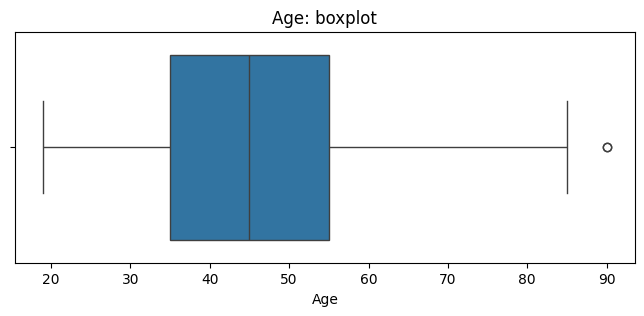

In [14]:

Q1, Q3 = df["Age"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers = df[(df["Age"] < lower) | (df["Age"] > upper)]
print(f"IQR bounds: {lower:.1f} to {upper:.1f}")
print("Potential Age outliers:", len(outliers))
display(outliers)

plt.figure(figsize=(8, 3))
sns.boxplot(x=df["Age"])
plt.title("Age: boxplot")
plt.show()

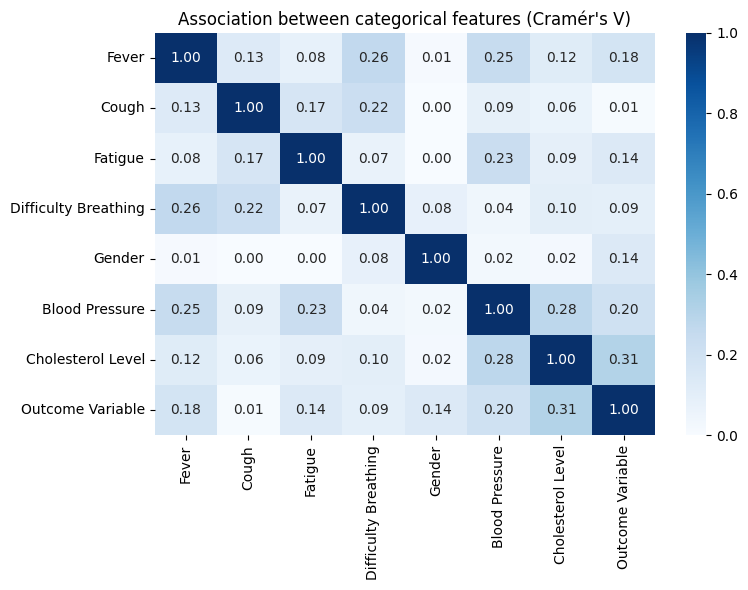

Outcome Variable
Negative    45.6
Positive    47.0
Name: Age, dtype: float64


In [15]:
from itertools import combinations
from scipy.stats import chi2_contingency

assoc_cols = [c for c in df.columns if c not in ["Disease", "Age"]]

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

mat = pd.DataFrame(1.0, index=assoc_cols, columns=assoc_cols)
for a, b in combinations(assoc_cols, 2):
    mat.loc[a, b] = mat.loc[b, a] = cramers_v(df[a], df[b])

plt.figure(figsize=(8, 6))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Association between categorical features (Cramér's V)")
plt.tight_layout()
plt.show()


print(df.groupby("Outcome Variable")["Age"].mean().round(1))

The association analysis was used to examine whether categorical features contained overlapping information. Higher Cramér's V values indicate stronger associations, while lower values indicate weaker associations. The results should be reviewed to determine whether any features provide redundant information. Age was the only numerical feature, so numerical multicollinearity between multiple continuous variables could not be assessed.

###B6. Analyze disease distribution

The target variable will be examined to determine the frequency of each disease category. This analysis will help identify whether the dataset is balanced or imbalanced.

Number of diseases: 116
Most frequent: Asthma - 23 records
Diseases with only 1 record: 61
Diseases with fewer than 5 records: 84


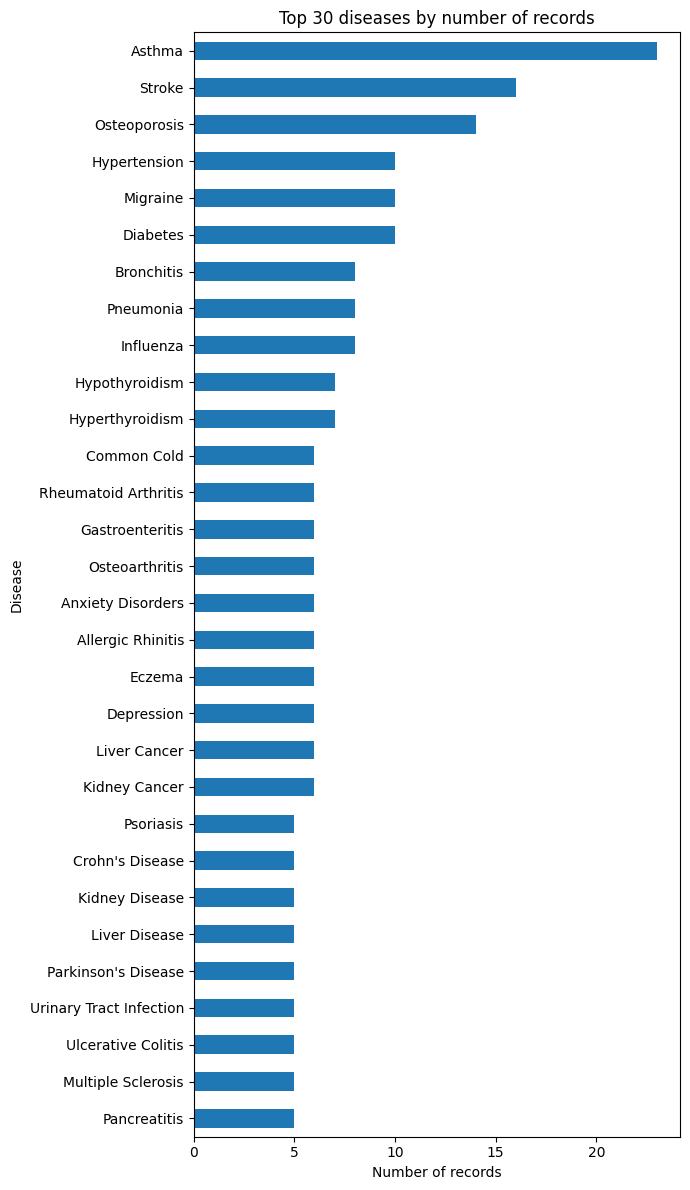

In [16]:
counts = df["Disease"].value_counts()
print("Number of diseases:", counts.shape[0])
print("Most frequent:", counts.index[0], "-", counts.iloc[0], "records")
print("Diseases with only 1 record:", (counts == 1).sum())
print("Diseases with fewer than 5 records:", (counts < 5).sum())

plt.figure(figsize=(7, 12))
counts.head(30).sort_values().plot(kind="barh")
plt.xlabel("Number of records")
plt.title("Top 30 diseases by number of records")
plt.tight_layout()
plt.show()

The disease distribution shows that the dataset is highly imbalanced. After removing duplicate records, Asthma was the most frequently represented disease, with 16 records. In contrast, 77 disease categories had only one observation each.

This imbalance may cause the model to perform better on frequently represented diseases than on less common diseases. Macro-averaged Recall was selected as the primary evaluation metric because it gives equal importance to each disease category. However, the limited number of observations per category remains a significant limitation when training and evaluating a multiclass classification model.

###B7. Analyze feature relationships

Visualizations will be used to examine possible relationships between patient characteristics and disease categories. These patterns may help identify features that contribute to disease classification.

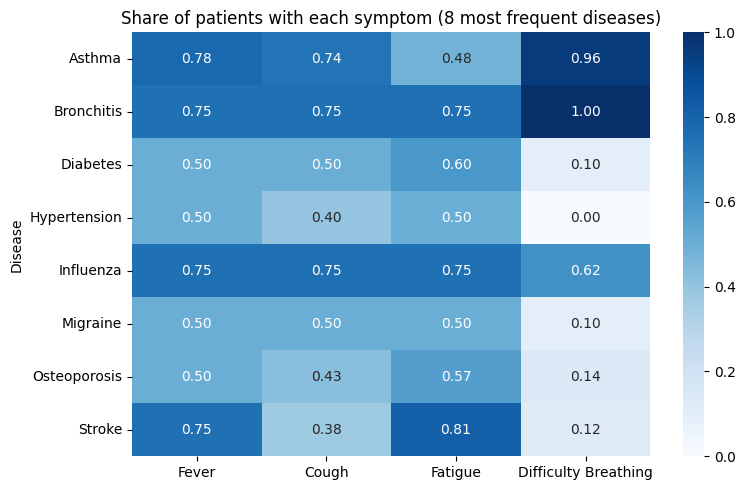

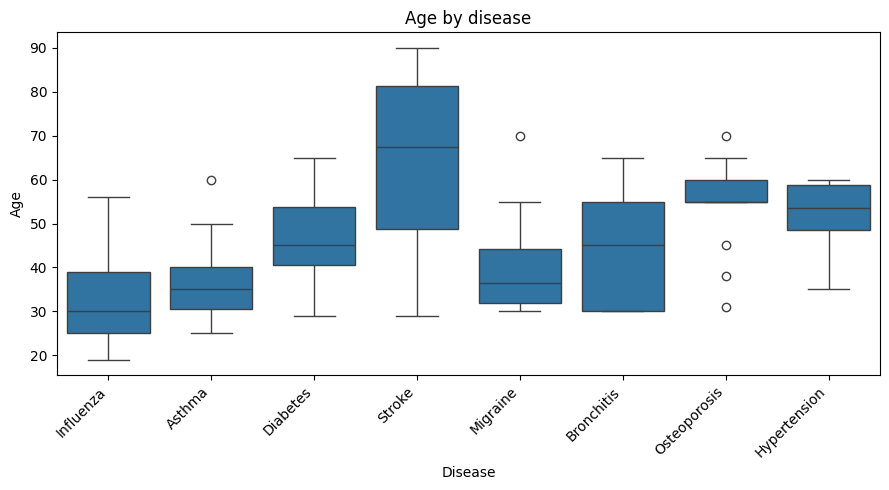

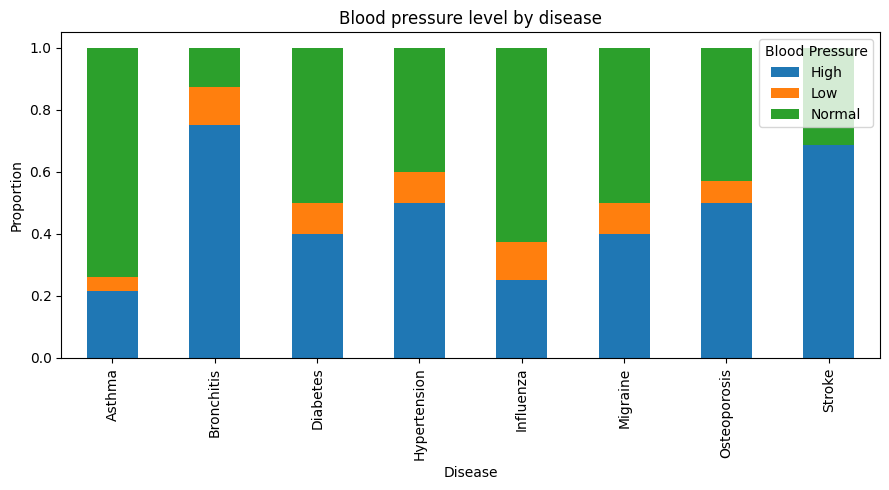

In [17]:
top = df["Disease"].value_counts().head(8).index
sub = df[df["Disease"].isin(top)]


symptoms = ["Fever", "Cough", "Fatigue", "Difficulty Breathing"]
rates = (sub[symptoms] == "Yes").groupby(sub["Disease"]).mean()
plt.figure(figsize=(8, 5))
sns.heatmap(rates, annot=True, fmt=".2f", cmap="Blues")
plt.title("Share of patients with each symptom (8 most frequent diseases)")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))
sns.boxplot(data=sub, x="Disease", y="Age")
plt.xticks(rotation=45, ha="right")
plt.title("Age by disease")
plt.tight_layout()
plt.show()


pd.crosstab(sub["Disease"], sub["Blood Pressure"], normalize="index").plot(
    kind="bar", stacked=True, figsize=(9, 5))
plt.ylabel("Proportion")
plt.title("Blood pressure level by disease")
plt.tight_layout()
plt.show()

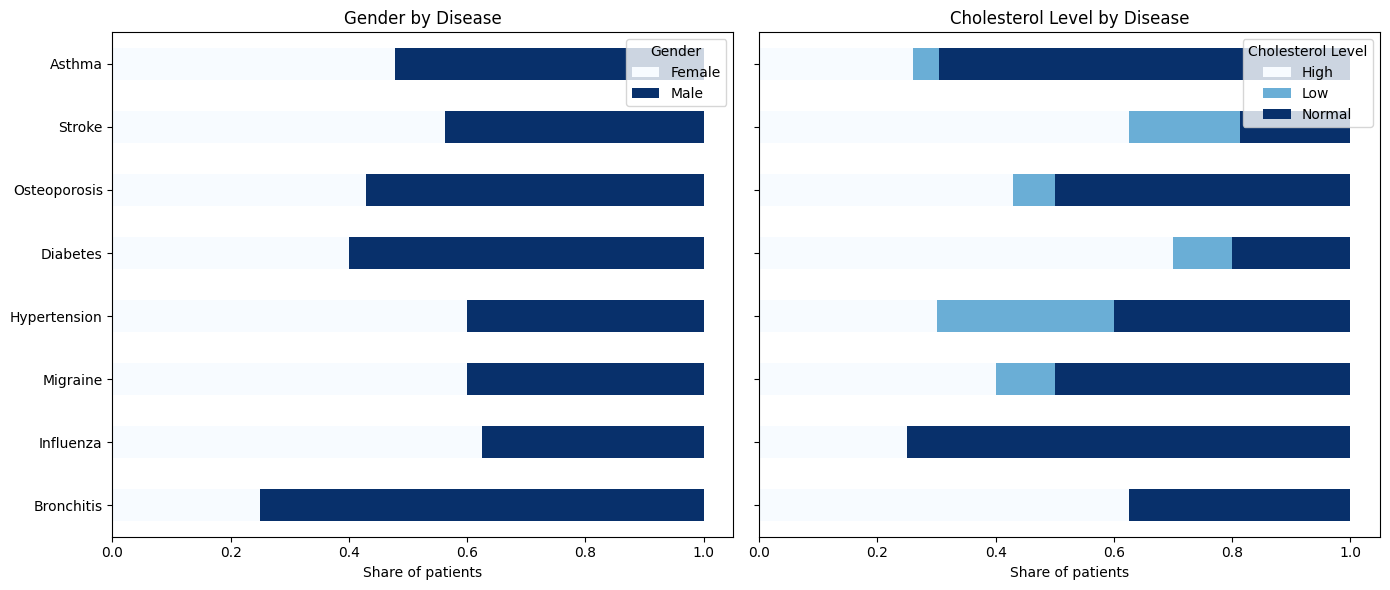

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


top_diseases = df["Disease"].value_counts().head(8).index
df_top = df[df["Disease"].isin(top_diseases)]
TARGET_COLUMN = "Disease"


fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, col in zip(axes, ["Gender", "Cholesterol Level"]):
    pd.crosstab(df_top[TARGET_COLUMN], df_top[col], normalize="index").loc[top_diseases][::-1] \
        .plot(kind="barh", stacked=True, ax=ax, colormap="Blues")
    ax.set_title(f"{col} by Disease")
    ax.set_xlabel("Share of patients")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

###B8. Check possible data leakage

The available features were examined to identify variables that might reveal information about the target variable. The Outcome Variable column requires special attention because its meaning and method of collection are not sufficiently established in the available dataset description. If it represents a diagnosis result or information obtained after disease identification, using it as an input feature could cause data leakage.

Therefore, the Outcome Variable column will be excluded from the model until its meaning and availability at prediction time can be verified. The Disease column will also be excluded from the input features because it is the target variable being predicted.

In [ ]:
display(pd.crosstab(df["Disease"], df["Outcome Variable"]).head(15))
print(df["Outcome Variable"].value_counts())
print("\nDisease column is the target and is excluded from the input features.")
print("Outcome Variable is excluded until its meaning and availability are verified.")

Outcome Variable,Negative,Positive
Disease,,
Acne,1,0
Allergic Rhinitis,5,1
Alzheimer's Disease,2,3
Anemia,1,0
Anxiety Disorders,3,3
Appendicitis,1,0
Asthma,5,18
Atherosclerosis,1,0
Autism Spectrum Disorder (ASD),1,0


Outcome Variable
Positive    186
Negative    163
Name: count, dtype: int64

Disease column is the target and is excluded from the input features.
Outcome Variable is excluded until its meaning and availability are verified.


##Preparation (Section C)

###C1. Remove duplicate records

Duplicate records will be removed to prevent repeated observations from affecting the model training process.

In [ ]:
df_clean = df.copy()


df_clean["Disease"] = df_clean["Disease"].replace({
    "Chronic Obstructive Pulmonary...": "Chronic Obstructive Pulmonary Disease (COPD)",
    "Urinary Tract Infection (UTI)": "Urinary Tract Infection",
})

before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", before - len(df_clean), "| shape:", df_clean.shape)
print("Diseases after merging labels:", df_clean["Disease"].nunique())

Duplicates removed: 49 | shape: (300, 10)
Diseases after merging labels: 114


###C2. Handle missing target values

Records without disease labels will be removed because they cannot be used for supervised classification.

In [ ]:
before = len(df_clean)
df_clean = df_clean.dropna(subset=["Disease"]).reset_index(drop=True)
print("Records without a disease label removed:", before - len(df_clean))


MIN_RECORDS = 7
vc = df_clean["Disease"].value_counts()
kept = vc[vc >= MIN_RECORDS].index
print(f"Removed {(vc < MIN_RECORDS).sum()} diseases with < {MIN_RECORDS} records; kept {len(kept)}")
df_model = df_clean[df_clean["Disease"].isin(kept)].reset_index(drop=True)
print("Modelling data:", df_model.shape)

Records without a disease label removed: 0
Removed 104 diseases with < 7 records; kept 10
Modelling data: (98, 10)


###C3. Separate input features and target

The dataset will be separated into independent variables (features) and the dependent variable (target). The disease column will serve as the classification target.

In [ ]:
EXCLUDE = ["Outcome Variable"]

X = df_model.drop(columns=["Disease"] + EXCLUDE)
y = df_model["Disease"]
print("Features:", X.columns.tolist())

Features: ['Fever', 'Cough', 'Fatigue', 'Difficulty Breathing', 'Age', 'Gender', 'Blood Pressure', 'Cholesterol Level']


###C4. Identify numeric and categorical variables

Numeric and categorical variables will be identified to determine the appropriate preprocessing methods for each feature type.

In [ ]:
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

Numeric: ['Age']
Categorical: ['Fever', 'Cough', 'Fatigue', 'Difficulty Breathing', 'Gender', 'Blood Pressure', 'Cholesterol Level']


###C5. Split the dataset

The dataset will be divided into training and testing sets using an 80:20 ratio. Stratified sampling will be applied to preserve the disease-category distribution in both sets.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Smallest class in training data:", y_train.value_counts().min())

Train: (78, 8) | Test: (20, 8)
Smallest class in training data: 5


###C6. Create preprocessing pipeline

A preprocessing pipeline will be created to handle missing values, categorical encoding, and numerical scaling. These transformations will be fitted only on training data during model evaluation to prevent data leakage.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])
print("Preprocessing pipeline created (fitted later, inside cross-validation).")

Preprocessing pipeline created (fitted later, inside cross-validation).


##Answers for Section B and C

##B. Summarize and Analyze Data

###B1. What does each column mean?

The dataset contains patient-related information, including symptoms and profile attributes such as age, gender, blood pressure, and cholesterol. Each column will be examined to determine its meaning, data type, and possible values. The disease or diagnosis column will be treated as the target variable.

###B2. How many values are missing, duplicated, impossible, or extreme?

Missing values, duplicate records, and possible outliers will be identified using Pandas functions and the IQR method. Their exact counts will be determined from the dataset inspection results.

###B3. How is the target distributed?

The disease categories will be examined using frequency counts and a bar chart. The distribution will determine whether the dataset is balanced or imbalanced. If some diseases have fewer records, Macro Recall and stratified splitting will help evaluate their representation.

###B4. Which features appear most related to the target?

Numeric and categorical features will be compared across disease categories using boxplots and stacked bar charts. The resulting visualizations will help identify possible relationships between patient characteristics and disease labels.

Numeric and categorical features will be compared across disease categories using boxplots and stacked bar charts. The resulting visualizations will help identify possible relationships between patient characteristics and disease labels.

B5. Which features are strongly related to each other?

A correlation heatmap will be used to examine relationships among numeric features. Highly correlated variables may contain redundant information and will be evaluated before deciding whether feature removal is necessary.

B6. What surprising pattern or hypothesis did exploration reveal?

The initial hypothesis is that certain combinations of patient symptoms and profile attributes may be associated with particular disease categories. This hypothesis will be examined through feature visualizations and the classification results.

B7. Does any feature look suspiciously predictive?

Features that directly contain disease labels, diagnosis information, or future treatment outcomes may cause data leakage. These features will be reviewed and excluded when they would not be available at the time of prediction.
C. Prepare Data
C1. For each data-quality problem, what did you do and why?

Duplicate records will be removed to prevent repeated observations from affecting the analysis. Missing values in input features will be handled through median imputation for numeric variables and most-frequent-value imputation for categorical variables. Possible outliers will be investigated rather than automatically removed.

C2. How did you split the data?

The dataset will be divided into 80% training data and 20% testing data using stratified sampling. The training data will be used for model development and cross-validation, while the test data will be reserved for the final evaluation.

C3. Which preparation steps learn from the data?

Imputation, scaling, and categorical encoding are preprocessing steps that learn information from the training data. These operations will be placed inside a Scikit-learn Pipeline to prevent information from validation folds from leaking into the training process.

C4. Which features did you remove or create?

The target variable will be removed from the input features to prevent target leakage. Constant columns will also be removed because they do not provide useful variation for classification. Additional feature engineering will be considered after evaluating the initial models.

C5. Which transformations did you apply?

Median imputation and standard scaling will be applied to numeric features. Categorical features will use most-frequent-value imputation and one-hot encoding. Scaling is particularly important for Logistic Regression and KNN because they are sensitive to differences in feature scales.

C6. Would every feature be available at the moment a real prediction must be made?

The selected input features should represent information available when the patient is assessed, such as symptoms and profile information. Diagnosis results and future treatment outcomes should not be used as predictors because they may reveal information that would not be available at prediction time.